<a href="https://colab.research.google.com/github/nrldalia/data-science-analytics-portfolio/blob/main/02_machine_learning/HousingAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# 🏠 Housing Value Prediction Using Linear Regression

## 📌 Project Overview

This project demonstrates supervised machine learning using Linear Regression to estimate median housing values from median household income.

The analysis uses the California Housing dataset, a commonly used educational machine learning dataset.

### 🎯 Objectives
1. Load and inspect housing data.
2. Assess data quality.
3. Explore the relationship between income and housing value.
4. Prepare training and testing datasets.
5. Train a Linear Regression model.
6. Evaluate model performance using MAE, MSE, RMSE, and R².
7. Visualize predictions and residuals.
8. Document findings and limitations.

### 🔬 Research Question

How effectively can median household income alone explain and predict median housing values?

### 💡 Hypotheses

**H1:** Higher median household income is associated with higher median housing values.

**H2:** A single-feature Linear Regression model can explain some variation in housing values but will not capture every factor influencing property values.

### 🧠 Machine Learning Approach

- Learning type: Supervised learning
- Algorithm: Linear Regression
- Input feature: Median household income (`MedInc`)
- Target variable: Median housing value (`MedHouseVal`)
- Evaluation: Held-out test dataset

This is an educational regression model, not a real-estate valuation system.



## 🛠️ 1. Environment Setup

### Objective
Import the libraries required for data analysis, visualization, model training, and evaluation.

### Libraries
- pandas and NumPy: Data manipulation
- Matplotlib and seaborn: Visualization
- scikit-learn: Machine learning
- pathlib: Output file management

Google Colab generally includes these libraries, so separate installation may not be necessary.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

sns.set_theme(style="whitegrid")

OUTPUT_DIR = Path("outputs/housing")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

print("Environment initialized successfully.")
print("Output directory:", OUTPUT_DIR.resolve())


Environment initialized successfully.
Output directory: /content/outputs/housing



## 📥 2. Data Ingestion

### Objective
Load the California Housing dataset and inspect its structure.

### Dataset Information
The California Housing dataset contains census block-group observations and housing-related features.

For this beginner project, only one predictor is used:

- `MedInc`: Median household income, expressed in units of $10,000.
- `MedHouseVal`: Median housing value, expressed in units of $100,000.

### Methodology
The dataset is loaded using scikit-learn.

The complete dataset is retained for initial inspection before selecting the feature and target.

### 🌐 Dataset Availability and Fallback

The primary dataset source is scikit-learn's California Housing dataset.

If the dataset download fails due to a server or network
error, the notebook attempts to load an alternative
California housing dataset from a public GitHub repository.

The fallback dataset is related but not identical to the
scikit-learn dataset.

For consistency, the analysis uses two standardized
column names:

- `MedInc`: Median household income
- `MedHouseVal`: Median housing value in $100,000 units

Model evaluation results may differ depending on which
dataset source is used.


In [6]:

import pandas as pd
from sklearn.datasets import fetch_california_housing

# Primary source: scikit-learn
# Fallback source: public California Housing CSV

try:
    housing = fetch_california_housing(as_frame=True)
    df = housing.frame.copy()
    print("Dataset loaded from scikit-learn.")

except Exception as error:
    print("Primary dataset source unavailable.")
    print("Attempting alternative source...")

    dataset_url = (
        "https://raw.githubusercontent.com/"
        "ageron/handson-ml2/master/datasets/"
        "housing/housing.csv"
    )

    raw_df = pd.read_csv(dataset_url)

    # The alternative dataset uses different column names
    df = raw_df.rename(columns={
        "median_income": "MedInc",
        "median_house_value": "MedHouseVal"
    })

    # Convert target from dollars to $100,000 units
    df["MedHouseVal"] = df["MedHouseVal"] / 100000

    # Keep the columns required for our project
    df = df[["MedInc", "MedHouseVal"]].copy()

    print("Alternative California Housing dataset loaded.")

print("\nDataset shape:", df.shape)
display(df.head())


/usr/local/lib/python3.13/dist-packages/sklearn/datasets/_base.py:1519: UserWarning: Retry downloading from url: https://ndownloader.figshare.com/files/5976036
  warnings.warn(f"Retry downloading from url: {remote.url}")


Primary dataset source unavailable.
Attempting alternative source...
Alternative California Housing dataset loaded.

Dataset shape: (20640, 2)


,MedInc,MedHouseVal
0,8.3252,4.526
1,8.3014,3.585
2,7.2574,3.521
3,5.6431,3.413
4,3.8462,3.422



### ✅ Data Ingestion Conclusion

The California Housing dataset has been loaded into a pandas DataFrame.

The dataset includes multiple housing and geographic variables, but this project deliberately uses a single predictor to demonstrate the fundamentals of Linear Regression.

A single-feature approach also makes the relationship between the predictor and target easier to visualize and interpret.



## 🧹 3. Data Quality Assessment

### Objective
Confirm that the selected predictor and target are suitable for regression analysis.

### Validation Checks
- Missing values
- Duplicate rows
- Numeric data types
- Minimum and maximum values
- Invalid or non-finite observations

### Hypothesis
The selected variables are expected to contain usable numeric observations.

### Analytical Consideration
Duplicate rows do not necessarily represent erroneous records because different census block groups can share identical feature values.


In [7]:

selected_columns = ["MedInc", "MedHouseVal"]

df_model = df[selected_columns].copy()

print("Missing values:")
print(df_model.isna().sum())

print("\nDuplicate rows:")
print(df_model.duplicated().sum())

print("\nData types:")
print(df_model.dtypes)

print("\nSummary statistics:")
display(df_model.describe().round(3))

print("\nNon-finite values:")
print(
    np.isfinite(df_model.to_numpy()).all()
)


Missing values:
MedInc         0
MedHouseVal    0
dtype: int64

Duplicate rows:
108

Data types:
MedInc         float64
MedHouseVal    float64
dtype: object

Summary statistics:


,MedInc,MedHouseVal
count,20640.000,20640.000
mean,3.871,2.069
std,1.900,1.154
min,0.500,0.150
25%,2.563,1.196
50%,3.535,1.797
75%,4.743,2.647
max,15.000,5.000



Non-finite values:
True


In [8]:

# Convert columns to numeric
for column in selected_columns:
    df_model[column] = pd.to_numeric(
        df_model[column],
        errors="coerce"
    )

# Replace infinite values with missing values
df_model = df_model.replace(
    [np.inf, -np.inf],
    np.nan
)

# Remove invalid observations
rows_before = len(df_model)

df_model = df_model.dropna(
    subset=selected_columns
)

# Median income and housing value must be positive
df_model = df_model[
    (df_model["MedInc"] > 0) &
    (df_model["MedHouseVal"] > 0)
].copy()

print("Rows before cleaning:", rows_before)
print("Rows after cleaning:", len(df_model))
print("Rows removed:", rows_before - len(df_model))

assert not df_model.empty
assert np.isfinite(df_model.to_numpy()).all()


Rows before cleaning: 20640
Rows after cleaning: 20640
Rows removed: 0



### ✅ Data Quality Conclusion

The selected predictor and target were checked for missing, invalid, and non-finite values.

Observations with invalid numeric values were excluded.

Duplicate rows were not automatically removed because identical numeric values may correspond to different census block groups.

The validated dataset is now ready for exploratory analysis.



## 📊 4. Exploratory Data Analysis

### Objective
Examine the relationship between median income and median housing value.

### Hypothesis
Higher median income is expected to be associated with higher median housing value.

### Methodology
- Plot the distribution of median income.
- Visualize income against housing value.
- Calculate Pearson correlation.

### Limitations
Correlation measures linear association, not causation.

The housing target is capped in this dataset, which can affect the appearance of the scatterplot and model residuals.


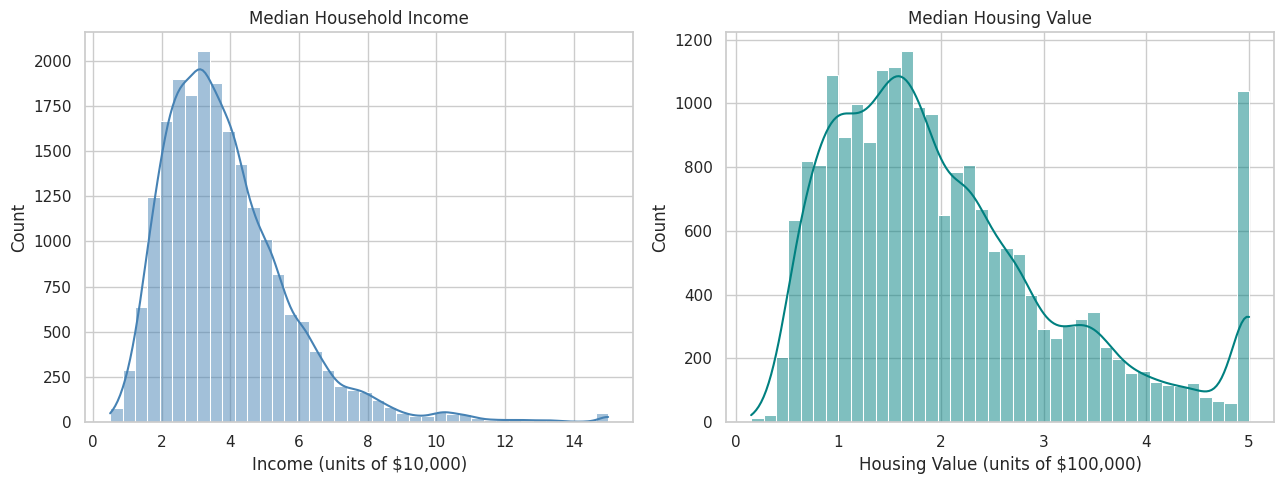

In [9]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(
    df_model["MedInc"],
    bins=40,
    kde=True,
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Median Household Income")
axes[0].set_xlabel("Income (units of $10,000)")

sns.histplot(
    df_model["MedHouseVal"],
    bins=40,
    kde=True,
    ax=axes[1],
    color="teal"
)

axes[1].set_title("Median Housing Value")
axes[1].set_xlabel("Housing Value (units of $100,000)")

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "housing_distributions.png",
    dpi=150
)
plt.show()


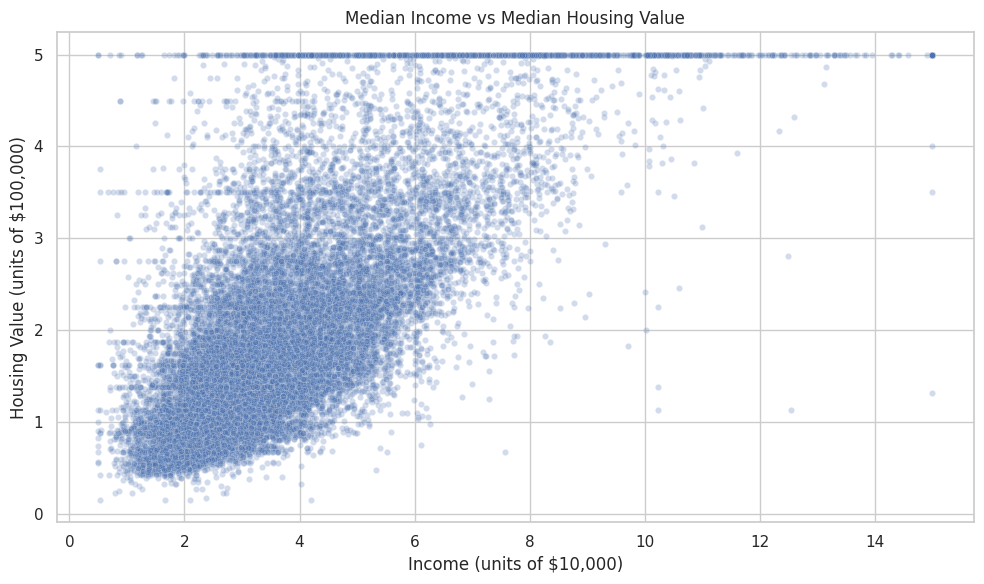

Pearson correlation: 0.688


In [10]:

correlation = df_model[
    ["MedInc", "MedHouseVal"]
].corr().iloc[0, 1]

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_model,
    x="MedInc",
    y="MedHouseVal",
    alpha=0.25,
    s=20
)

plt.title("Median Income vs Median Housing Value")
plt.xlabel("Income (units of $10,000)")
plt.ylabel("Housing Value (units of $100,000)")

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "income_vs_housing.png",
    dpi=150
)
plt.show()

print(f"Pearson correlation: {correlation:.3f}")



### 🔍 Exploratory Analysis Conclusion

The scatterplot and correlation coefficient help assess whether median income and housing value have a positive linear relationship.

The visualization also reveals dispersion around the relationship, suggesting that income alone may not fully explain housing values.

The capped housing-value observations should be considered when interpreting the model.

The next stage evaluates whether the observed relationship generalizes to held-out observations.



## ✂️ 5. Training and Testing Data

### Objective
Separate observations used for model training from observations used for evaluation.

### Methodology
- 80% training data
- 20% testing data
- Random state: 42

### Why This Matters
Evaluating a model on the same observations used during training can produce overly optimistic results.

A held-out test set provides a more realistic estimate of predictive performance on unseen observations from a similar data distribution.

### Limitation
A random split does not specifically test whether the model generalizes to different geographic areas or future periods.


In [11]:

X = df_model[["MedInc"]]
y = df_model["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

assert len(X_train) + len(X_test) == len(df_model)
assert X_train.index.intersection(X_test.index).empty


Training observations: 16512
Testing observations: 4128



### ✅ Data Splitting Conclusion

The dataset was divided into training and testing subsets.

The training data will be used to estimate model parameters.

The test data will be reserved for evaluating model predictions.

The fixed random state ensures that the same observations are selected when the notebook is rerun with the same dataset and software behavior.



## 🤖 6. Model Training

### Objective
Train a Linear Regression model to estimate median housing value using median household income.

### Model Equation

Predicted Housing Value = Intercept + (Coefficient × Median Income)

### Methodology
The model learns the coefficient and intercept from the training data by minimizing squared prediction errors.

### Hypothesis
The estimated income coefficient will be positive, indicating that higher median income is associated with higher predicted housing values.

### Important Distinction
A regression coefficient represents an estimated association within this model. It does not prove that income causes changes in property values.


In [12]:

model = LinearRegression()

model.fit(X_train, y_train)

coefficient = model.coef_[0]
intercept = model.intercept_

print("LINEAR REGRESSION MODEL")
print("-----------------------")
print(f"Intercept: {intercept:.4f}")
print(f"Income coefficient: {coefficient:.4f}")

print(
    f"\nPredicted Housing Value = "
    f"{intercept:.4f} + "
    f"({coefficient:.4f} × Median Income)"
)


LINEAR REGRESSION MODEL
-----------------------
Intercept: 0.4446
Income coefficient: 0.4193

Predicted Housing Value = 0.4446 + (0.4193 × Median Income)



### ✅ Model Training Conclusion

The Linear Regression model was fitted using the training observations.

The coefficient indicates the estimated change in median housing value for a one-unit increase in median income.

Because the original dataset expresses income in units of $10,000 and housing value in units of $100,000, these measurement scales must be considered when interpreting the coefficient.

The model has been trained, but its usefulness must be assessed using predictions on the test dataset.



## 📏 7. Model Evaluation

### Objective
Evaluate how accurately the trained regression model estimates housing values on unseen test observations.

### Evaluation Metrics

**Mean Absolute Error (MAE)**
The average absolute difference between actual and predicted values.

**Mean Squared Error (MSE)**
The average squared prediction error. Larger errors receive greater penalties.

**Root Mean Squared Error (RMSE)**
The square root of MSE, expressed in the original target units.

**R-squared (R²)**
Measures how much of the variation in the test target is explained relative to predicting the test-set mean.

R² is not a classification accuracy percentage.

### Baseline Comparison
The regression model will also be compared with a simple baseline that predicts the training-set mean for every test observation.

### Hypothesis
The trained regression model will outperform the mean-prediction baseline if median income contains useful predictive information.


In [13]:

# Predict housing values
y_pred = model.predict(X_test)

# Simple baseline: training-set mean
baseline_pred = np.full(
    shape=len(y_test),
    fill_value=y_train.mean()
)

def evaluate_regression(actual, predicted):
    mse = mean_squared_error(actual, predicted)

    return {
        "MAE": mean_absolute_error(actual, predicted),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(actual, predicted)
    }

model_metrics = evaluate_regression(y_test, y_pred)
baseline_metrics = evaluate_regression(
    y_test,
    baseline_pred
)

comparison = pd.DataFrame(
    [baseline_metrics, model_metrics],
    index=["Mean Baseline", "Linear Regression"]
)

display(comparison.round(4))


,MAE,MSE,RMSE,R2
Mean Baseline,0.9061,1.3107,1.1449,-0.0002
Linear Regression,0.6299,0.7091,0.8421,0.4589


In [14]:

mae_dollars = model_metrics["MAE"] * 100_000
rmse_dollars = model_metrics["RMSE"] * 100_000

print("LINEAR REGRESSION PERFORMANCE")
print("-----------------------------")
print(f"MAE:  ${mae_dollars:,.2f}")
print(f"RMSE: ${rmse_dollars:,.2f}")
print(f"R²:   {model_metrics['R2']:.4f}")

if model_metrics["MAE"] < baseline_metrics["MAE"]:
    print("\nThe model outperforms the mean baseline on MAE.")
else:
    print("\nThe model does not outperform the baseline on MAE.")


LINEAR REGRESSION PERFORMANCE
-----------------------------
MAE:  $62,990.87
RMSE: $84,209.01
R²:   0.4589

The model outperforms the mean baseline on MAE.



### 📊 Model Evaluation Conclusion

The regression model was evaluated using observations excluded from training.

MAE and RMSE measure prediction error, while R² describes model performance relative to a mean-prediction benchmark.

Comparing the model against a simple baseline helps determine whether using median income provides a meaningful improvement.

Because this is a single-feature model, unexplained variation is expected.

Model performance should be interpreted in the context of the target units, the dataset's capped housing values, and the absence of other relevant predictors.



## 📈 8. Prediction Visualization

### Objective
Compare actual housing values with the fitted regression relationship.

### Methodology
The test observations are displayed as scatter points.

The regression line is generated using a sorted sequence of income values so that the line is drawn correctly.

### Expected Interpretation
The fitted line represents the model's estimated linear relationship.

Points farther from the line have larger prediction errors.


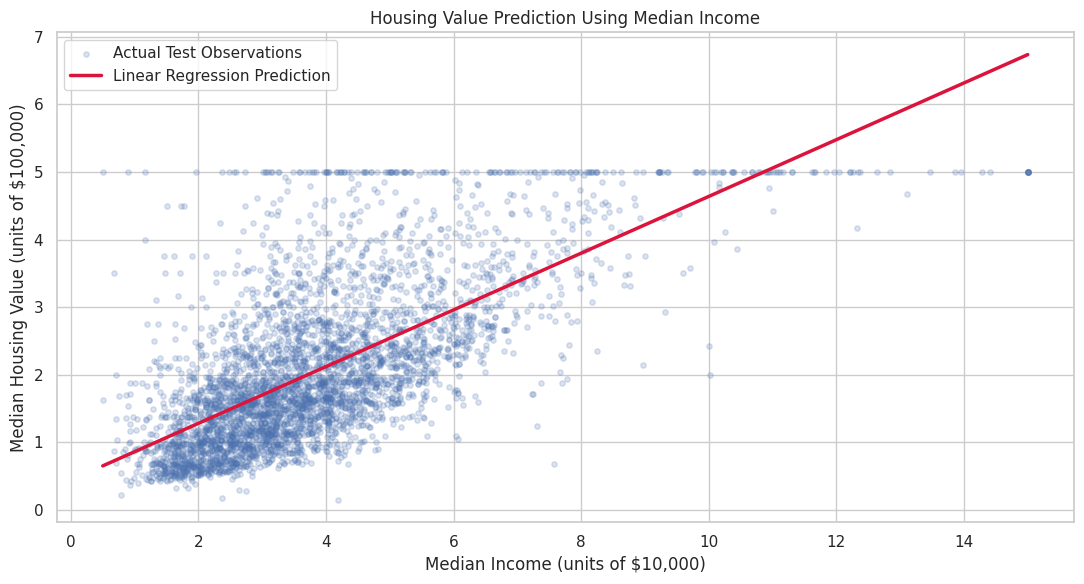

In [15]:

# Create a sorted sequence for a smooth regression line
income_line = pd.DataFrame({
    "MedInc": np.linspace(
        X_test["MedInc"].min(),
        X_test["MedInc"].max(),
        200
    )
})

predicted_line = model.predict(income_line)

plt.figure(figsize=(11, 6))

plt.scatter(
    X_test["MedInc"],
    y_test,
    alpha=0.20,
    s=15,
    label="Actual Test Observations"
)

plt.plot(
    income_line["MedInc"],
    predicted_line,
    color="crimson",
    linewidth=2.5,
    label="Linear Regression Prediction"
)

plt.title("Housing Value Prediction Using Median Income")
plt.xlabel("Median Income (units of $10,000)")
plt.ylabel("Median Housing Value (units of $100,000)")
plt.legend()

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "regression_prediction.png",
    dpi=150
)
plt.show()



### 🔍 Prediction Visualization Conclusion

The regression line summarizes the estimated relationship between median income and median housing value.

The dispersion of actual observations around the line illustrates the limitations of using income as the only predictor.

The visualization is useful for interpreting the model, but numerical evaluation metrics remain necessary for assessing prediction performance.



## 🔎 9. Residual Analysis

### Objective
Examine differences between actual and predicted housing values.

### Definition
Residual = Actual Value - Predicted Value

### Methodology
Plot residuals against predicted housing values.

### Analytical Consideration
A residual plot can reveal systematic patterns, changing error spread, or limitations in the assumed linear relationship.

A residual plot alone does not establish whether all statistical model assumptions are satisfied.


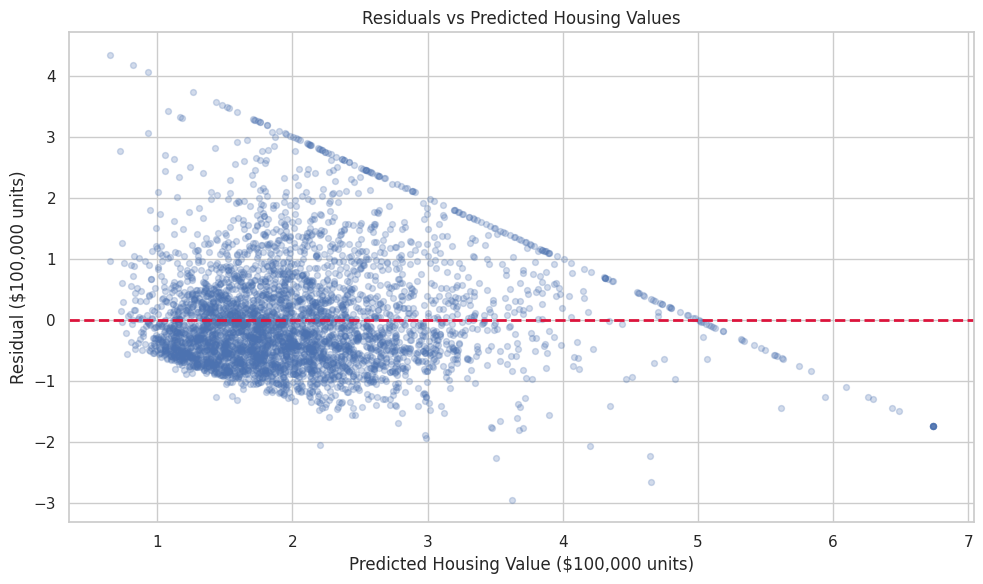

Mean residual: 0.0042
Residual standard deviation: 0.8421


In [16]:

residuals = y_test.to_numpy() - y_pred

plt.figure(figsize=(10, 6))

plt.scatter(
    y_pred,
    residuals,
    alpha=0.25,
    s=18
)

plt.axhline(
    y=0,
    color="crimson",
    linestyle="--",
    linewidth=2
)

plt.title("Residuals vs Predicted Housing Values")
plt.xlabel("Predicted Housing Value ($100,000 units)")
plt.ylabel("Residual ($100,000 units)")

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "regression_residuals.png",
    dpi=150
)
plt.show()

print(f"Mean residual: {residuals.mean():.4f}")
print(f"Residual standard deviation: {residuals.std():.4f}")



### ✅ Residual Analysis Conclusion

Residual analysis provides an additional perspective on regression performance beyond aggregate error metrics.

Any visible pattern or uneven spread in the residuals may indicate that a simple linear relationship does not fully describe the data.

The capped target values and omitted predictors are important limitations of this educational model.



## 💾 10. Save and Validate Results

### Objective
Export model predictions and evaluation metrics for reproducibility.

### Expected Outputs
- Regression prediction chart
- Residual chart
- Feature distribution chart
- Prediction results CSV
- Model evaluation CSV

### Validation
Basic assertions will verify that predictions are finite, output files exist, and the number of predictions matches the test dataset.


In [17]:

predictions_df = pd.DataFrame({
    "Median_Income": X_test["MedInc"].to_numpy(),
    "Actual_Housing_Value": y_test.to_numpy(),
    "Predicted_Housing_Value": y_pred,
    "Residual": residuals
})

predictions_df.to_csv(
    OUTPUT_DIR / "housing_predictions.csv",
    index=False
)

comparison.to_csv(
    OUTPUT_DIR / "housing_model_metrics.csv"
)

assert len(predictions_df) == len(X_test)
assert np.isfinite(y_pred).all()
assert not predictions_df.isna().any().any()

required_files = [
    "housing_distributions.png",
    "income_vs_housing.png",
    "regression_prediction.png",
    "regression_residuals.png",
    "housing_predictions.csv",
    "housing_model_metrics.csv"
]

for filename in required_files:
    assert (OUTPUT_DIR / filename).is_file()

print("All housing model validation checks passed.")
print("Results saved to:", OUTPUT_DIR.resolve())

display(predictions_df.head())


All housing model validation checks passed.
Results saved to: /content/outputs/housing


,Median_Income,Actual_Housing_Value,Predicted_Housing_Value,Residual
0,1.6812,0.47700,1.149589,-0.672589
1,2.5313,0.45800,1.506069,-1.048069
2,3.4801,5.00001,1.903937,3.096073
3,5.7376,2.18600,2.850594,-0.664594
4,3.7250,2.78000,2.006633,0.773367



## 🏁 Final Conclusion — Housing Value Regression

This project demonstrated a complete beginner-level supervised learning workflow using Linear Regression.

### Skills Demonstrated
- Data ingestion and validation
- Exploratory data analysis
- Feature and target selection
- Training and testing separation
- Linear Regression
- Baseline comparison
- MAE, MSE, RMSE, and R² evaluation
- Prediction and residual visualization
- Exporting model results

### Key Learning
A regression model should not be judged solely by whether it produces predictions.

Its performance must be compared against a baseline and evaluated using suitable metrics.

### Limitations
- Only one predictor was used.
- Housing values in the dataset are capped.
- Geographic effects were not modeled.
- A random split does not measure performance on entirely new geographic regions.
- The model is not intended for real-world property appraisal.

### Future Improvements
- Multiple Linear Regression
- Regularized regression
- Additional housing features
- Cross-validation
- Geographic generalization tests

**Project Level:** Beginner

**Machine Learning Type:** Supervised Learning

**Algorithm:** Linear Regression
